# Import 
Import all the necessary library

In [3]:
import os
import numpy as np
import torch
import torchvision.models as models
import torchvision.transforms as T
from PIL import Image
from tqdm import tqdm
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.preprocessing import normalize
import shutil
import umap
import hdbscan
import hashlib




# Detecting Outliers

We initially considered identifying outliers by detecting a **green color range** in the images (accounting for both *Shrek* and the *green blob* images). However, we found this approach to be **suboptimal**, as it would have been highly sensitive to lighting conditions, color variations, and background noise, and it would likely have required **manual post-filtering** to remove false positives.

---

### Clustering-based Approach

Instead, we opted for a **clustering-based strategy**, which is more robust and scalable.  
Our objective was to divide the dataset into **exactly three clusters**:

- **Shrek images**
- **Green blob images**
- **Real images**

This separation allowed us to automatically identify and remove the first two categories as outliers, without relying on handcrafted color thresholds.

---

### Feature Extraction

To represent images in a meaningful way, we leveraged **semantic embeddings** extracted from a deep neural network:

- We loaded a **pretrained ResNet50** model.
- For each image, we extracted high-level feature embeddings from the network.
- These embeddings capture **semantic and structural information**, rather than raw pixel colors.

All embeddings were stored in a file called:

```text
embeddings.csv



In [4]:
# Load ResNet50
model = models.resnet50(pretrained=True)
model.eval()

# Replace classifier with identity → output 2048-d embedding
model.fc = torch.nn.Identity()

print("Model loaded. Output dimension:", model(torch.randn(1,3,224,224)).shape[1])


/home/enange/miniconda3/envs/ANN/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/enange/miniconda3/envs/ANN/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model loaded. Output dimension: 2048


In [ ]:
# Apply Resnet50 transformations
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def get_embedding(img_path):
    img = Image.open(img_path).convert("RGB")
    x = transform(img).unsqueeze(0)

    with torch.no_grad():
        # Extract the embeddings of images from the model Resnet50
        emb = model(x)

    return emb.squeeze().numpy()




This section extracts feature embeddings from all images contained in a specified folder.  
Each image is processed individually using a pre-defined embedding function, producing a compact numerical representation suitable for similarity analysis, clustering, the latter will be used later.  


In [ ]:
def extract_embeddings(folder):
    
    valid_ext = {".png"}
    
    files = [
        f for f in os.listdir(folder)
        if os.path.splitext(f.lower())[1] in valid_ext
    ]
    
    print(f"Found {len(files)} images.")

    embeddings = []
    filenames = []

    # Take .png images from the folder
    for fname in tqdm(files):
        fpath = os.path.join(folder, fname)

        try:
            emb = get_embedding(fpath)
            embeddings.append(emb)
            filenames.append(fname)
        except Exception as e:
            print(f"[ERROR] {fname}: {e}")

    # Save embeddings
    embeddings = np.array(embeddings)

    return filenames, embeddings


In [ ]:
FOLDER = "train_dataNoMask"

filenames, embeddings = extract_embeddings(FOLDER)

# Save numpy file
np.save("embeddings.npy", embeddings)
np.save("filename.npy", filenames)

# Save CSV (filenames + vector)
df = pd.DataFrame(embeddings)
df.insert(0, "filename", filenames)
df.to_csv("embeddings.csv", index=False)

print("Saved embeddings to:")
print(" - embeddings.npy")
print(" - embeddings.csv")


Found 691 images.


100%|██████████| 691/691 [00:52<00:00, 13.08it/s]


Saved embeddings to:
 - embeddings.npy
 - embeddings.csv


In [ ]:
df.head()

,filename,0,1,2,3,4,5,6,7,8,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
0,img_0564.png,0.120863,0.380863,0.045546,0.021729,0.275032,0.100356,0.118765,0.641789,0.924492,...,0.228040,0.097737,0.131594,0.099672,0.644631,0.042822,0.128378,0.852585,0.282179,1.236178
1,img_0202.png,0.090861,0.029702,0.032055,0.608573,0.157041,1.177052,0.099469,0.231626,0.036214,...,0.094582,1.017557,0.029294,0.053490,0.910694,0.034169,0.200948,0.762845,0.909324,0.224721
2,img_0216.png,0.043082,0.424655,0.049896,0.000057,0.222286,0.227692,0.141605,0.085907,0.239997,...,0.114172,0.187030,0.203329,0.226456,0.302529,0.065459,0.062766,0.733107,0.372395,0.325334
3,img_0570.png,0.131739,0.243963,0.008593,0.000000,0.063796,0.302360,0.274724,0.339249,0.000000,...,0.015629,0.062771,0.021303,0.087191,0.191520,0.008962,0.000000,0.538032,0.160714,0.794589
4,img_0558.png,0.438194,0.163380,0.595658,1.145029,0.260211,1.602430,0.036741,0.744480,0.030611,...,1.037709,0.501911,0.379461,0.385950,0.235317,0.039524,0.907337,0.296697,0.047136,0.192743


## Dimensionality Reduction before Clustering

##### Why does it matter?
1) **Removes feature redundancy**  
   - Many features in high-dimensional representations are correlated or redundant.  
   - Dimensionality reduction compresses the information into fewer, more informative dimensions.

2) **Denoises the data**  
   - High-dimensional spaces contain many directions dominated by noise rather than signal.  
   - Reducing dimensionality helps filter out these noisy components, improving the signal-to-noise ratio.

3) **Makes distances meaningful**  
   - In high-dimensional spaces, we encounter the **curse of dimensionality**:  
     the distance between the nearest and farthest neighbors tends to become almost identical.  
   - As a consequence, distance-based methods struggle to distinguish between close and far points.


##### Our Objective

Our goal was to use **HDBSCAN**, a **density-based clustering algorithm** that identifies clusters by grouping samples according to a distance metric (in our case, **Euclidean distance**).

HDBSCAN relies heavily on:
- local neighborhoods,
- distance distributions,
- and density contrasts between regions of the space.

In a high-dimensional setting, these assumptions break down:
- data becomes extremely sparse,
- local densities are poorly defined,
- nearest-neighbor distances lose discriminative power.

As a result, without dimensionality reduction, HDBSCAN tends to either:
- label most points as noise, or  
- fail to identify meaningful clusters.

For this reason, **performing dimensionality reduction before running HDBSCAN is crucial**.  
By projecting the data into a lower-dimensional space, we restore meaningful density variations and stabilize neighborhood relationships.


##### Why UMAP?

To achieve this, we used **UMAP (Uniform Manifold Approximation and Projection)**.

UMAP is particularly well-suited for this task because:
- it preserves **local neighborhood structure**, which is essential for density-based methods,
- it captures **non-linear manifolds** commonly found in deep learning embeddings,
- it increases the contrast between dense and sparse regions,
- and it produces a representation where clusters become more compact and separable.

In this transformed space:
- dense regions correspond to true clusters,
- sparse regions naturally emerge as noise,
- and HDBSCAN can reliably estimate density and extract stable clusters.


In [5]:

# Load embeddings
embeddings = np.load("embeddings.npy")

# reduce dimensionality
umap_embed = umap.UMAP(n_neighbors=10, min_dist=0.1, metric='cosine').fit_transform(embeddings)

# cluster with HDBSCAN
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=20,
    metric='euclidean'
)
labels = clusterer.fit_predict(umap_embed)

# Save
pd.DataFrame({"filename": np.load("filename.npy"), "cluster": labels}).to_csv("clustered_images.csv", index=False)


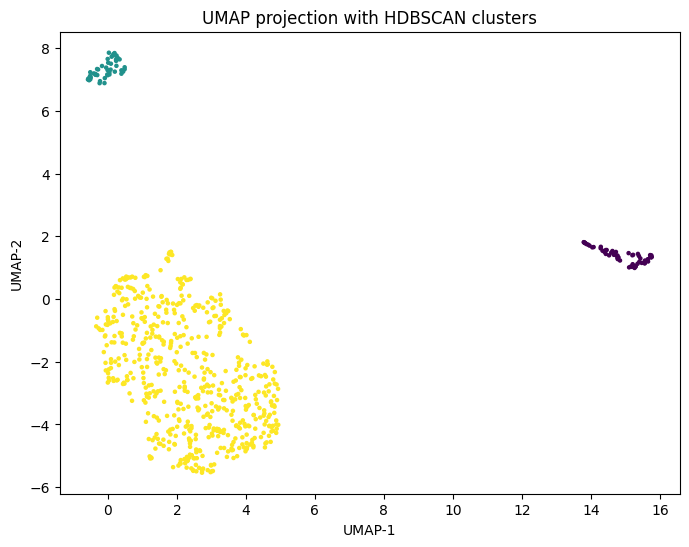

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    umap_embed[:, 0],
    umap_embed[:, 1],
    c=labels,
    s=5
)
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.title("UMAP projection with HDBSCAN clusters")
plt.legend()
plt.show()


Number of samples per class:
Shrek: 60
Blob: 50
Real Data: 581


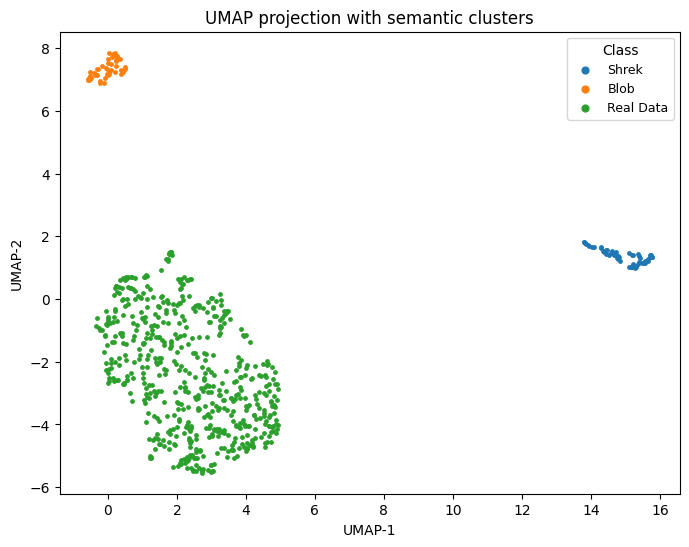

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Map cluster IDs to semantic names
cluster_name_map = {
    0: "Shrek",
    1: "Blob",
    2: "Real Data",
    -1: "Noise"
}

# Get unique labels and counts
unique_labels, counts = np.unique(labels, return_counts=True)

print("Number of samples per class:")
for lab, cnt in zip(unique_labels, counts):
    name = cluster_name_map.get(lab, f"Unknown ({lab})")
    print(f"{name}: {cnt}")

# Plot UMAP with semantic legend
plt.figure(figsize=(8, 6))

for lab in unique_labels:
    mask = labels == lab
    name = cluster_name_map.get(lab, f"Unknown ({lab})")

    plt.scatter(
        umap_embed[mask, 0],
        umap_embed[mask, 1],
        s=6,
        label=name
    )

plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.title("UMAP projection with semantic clusters")

plt.legend(
    title="Class",
    markerscale=2,
    fontsize=9,
    title_fontsize=10,
    loc="best"
)

plt.show()


# Visualize Clustering

The clustering process assigns a numerical ID to each discovered cluster.  
These cluster IDs are used to reference and inspect groups of images sharing similar visual characteristics.

1. Shrek's Images
2. Blob's Images
3. Tissues' Images







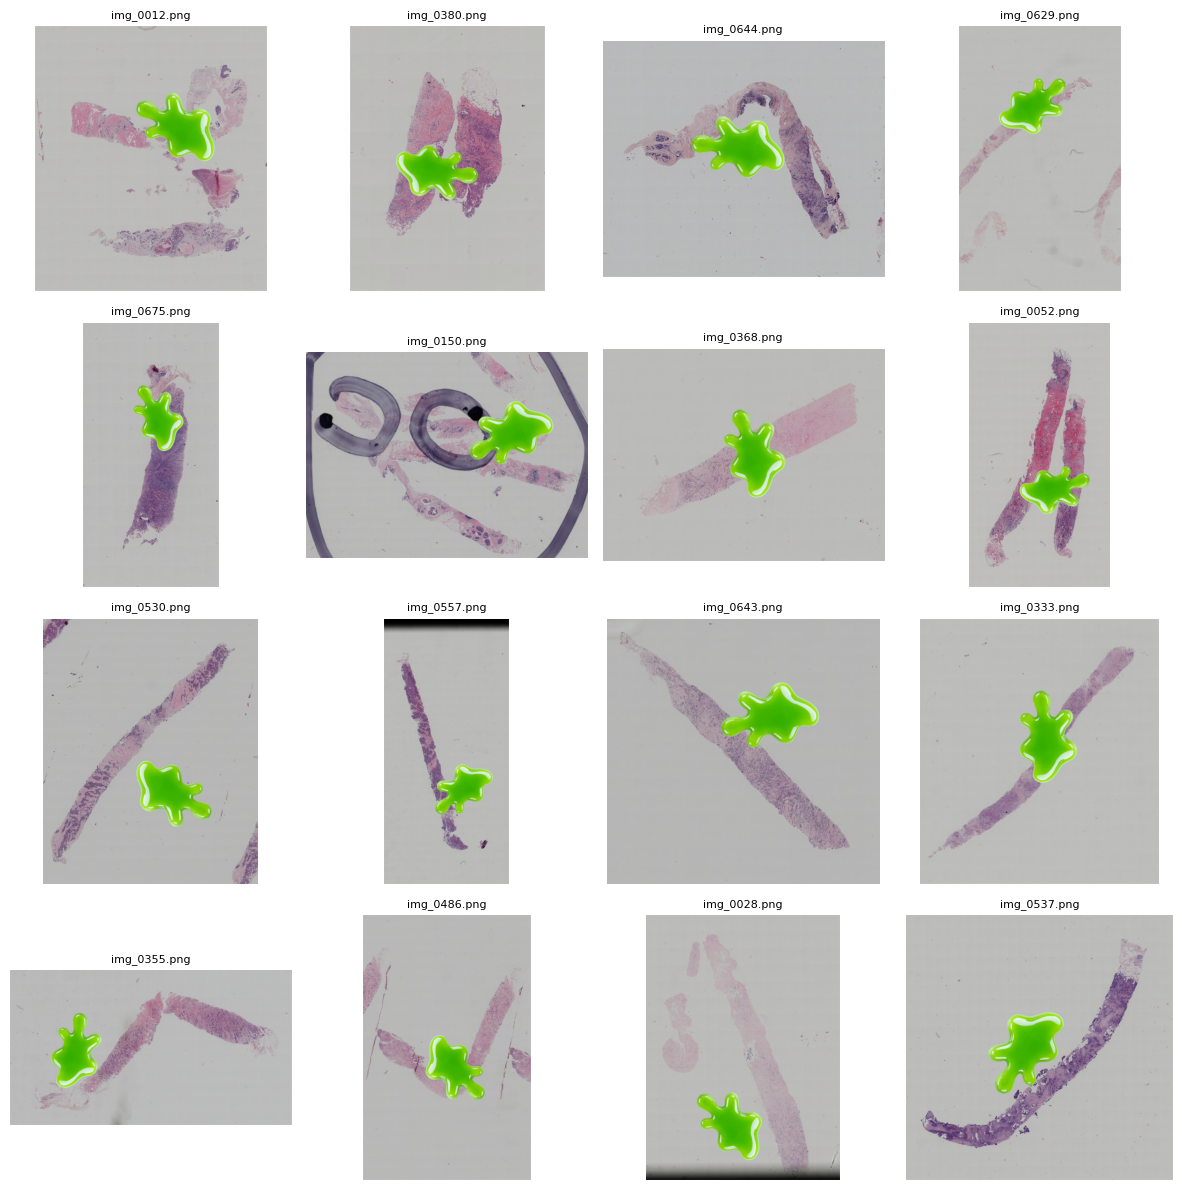

In [ ]:
# Load the clustering results
df = pd.read_csv("clustered_images.csv")

# Select images from cluster 1
cluster_id = 1      # 0: Shrek, 1: Blob, 2: True data
# Folder where images are stored
FOLDER = "train_dataNoMask"

cluster_files = df[df["cluster"] == cluster_id]["filename"].tolist()

# Display images (let's show 16 images in a 4x4 grid as an example)
n_images = min(16, len(cluster_files))
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i, ax in enumerate(axes.flatten()):
    if i < n_images:
        img_path = os.path.join(FOLDER, cluster_files[i])
        img = mpimg.imread(img_path)
        ax.imshow(img)
        ax.set_title(cluster_files[i], fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()


To be sure of our cluster division we quickly visualized the produced output folders

In [ ]:
# Load clustering results
df = pd.read_csv("clustered_images.csv")

# Folder where original images are
FOLDER = "train_dataNoMask"

cluster_mapping = ["Cshrek", "Cblob", "Cnormal"]

# Choose the cluster you want to extract

for cluster in range(len(df["cluster"].unique())):
    cluster_files = df[df["cluster"] == cluster]["filename"].tolist()

    # Create a new folder for this cluster
    output_folder = f"train_data_{cluster_mapping[cluster]}"
    os.makedirs(output_folder, exist_ok=True)

    # Copy images to the new folder
    for filename in cluster_files:
        src_path = os.path.join(FOLDER, filename)
        dst_path = os.path.join(output_folder, filename)
        shutil.copy2(src_path, dst_path)  

    print(f"Copied {len(cluster_files)} images to '{output_folder}'")


Copied 60 images to 'train_data_Cshrek'
Copied 50 images to 'train_data_Cblob'
Copied 581 images to 'train_data_Cnormal'


In [ ]:

noshrek_folder = "train_data_NOSHREK"
shutil.copytree("train_data_Cnormal", noshrek_folder, dirs_exist_ok=True)
#shutil.copytree("train_data_Cblob", noshrek_folder, dirs_exist_ok=True)


mask_folder = "train_data"

# scan NOSHREK images
for fname in os.listdir(noshrek_folder):
    if fname.startswith("img_"):
        
        # extract ID
        mask_name = fname.replace("img_", "mask_")
        # build mask filename
        mask_path = os.path.join(mask_folder, mask_name)
        
        # check if mask exists
        if os.path.exists(mask_path):
            # copy it into output folder
            shutil.copy2(mask_path, os.path.join(noshrek_folder, mask_name))
        else:
            print(f"Mask NOT found for: {fname}")

print("Done.")

Done.


---
#### NOTE: THE FOLLOWING PART OF THE CODE WAS DONE BEFORE THE DATASET ADJUSTEMENT
---


# Blob Detection

Before realizing that the green blobs were duplicates of images already present in the dataset, we adopted this approach to **remove the green blobs while preserving the underlying images**, in order to avoid discarding a large number of samples.

This step focuses on identifying and eliminating **green-colored regions** from the images using **HSV color thresholding**.  
A binary mask is first created to isolate pixels within the target green range. The mask is then refined through **morphological dilation** and **contour filling**, ensuring that the detected regions are spatially coherent and fully covered.

Finally, the identified blob regions are removed from the original images, and the cleaned outputs are saved for further analysis.

This procedure allowed us to mitigate the impact of artificial artifacts while retaining as much useful visual information as possible from the dataset.



In [ ]:
#os.environ["QT_QPA_PLATFORM"] = "xcb"


## Setting Parameters for green
lower_green = np.array([35, 140, 100])
upper_green = np.array([80, 255, 255])

## Starting see all the image 
for filename in os.listdir("train_data_Cblob/"):

    img = cv2.imread(f"train_data_Cblob/{filename}")

    # Check if image loaded successfully
    if img is None:
        print("Error: Image not found.")
        exit()

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, lower_green, upper_green)

    ## Dilate the mask
    kernel = np.ones((9, 9), np.uint8)
    mask = cv2.dilate(mask, kernel, iterations=4)


    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask_filled = np.zeros_like(mask)
    cv2.drawContours(mask_filled, contours, -1, 255, thickness=cv2.FILLED)

    #find the green on the mask
    ys, xs = np.where(mask_filled > 0)

    if len(ys) > 0:
        number_of_pixels = len(ys)
        img[ys, xs] = 0
        path = f"{noshrek_folder}/{filename}"
        success = cv2.imwrite(filename=path, img=img)

print("Done.")

Done.


In [ ]:
prefix = f"{noshrek_folder}/"

for filename in tqdm(os.listdir(noshrek_folder)):
    if filename.startswith("img_"):
        img_name = prefix + filename
        mask_name = img_name.replace("img_","mask_")


        img = cv2.cvtColor(cv2.imread(img_name), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_name, cv2.IMREAD_GRAYSCALE)

        res = cv2.bitwise_and(img, img, mask=mask)
        
        path = f"train_data_FINAL/{filename}"
        cv2.imwrite(filename=path, img=res)

100%|██████████| 1162/1162 [00:23<00:00, 49.10it/s]


# Delete duplicates
In the first dataset there were a lot of duplicates and some of that had different label. This code identifies these outliers, prunes one of the duplicates and completely removes same images with different labels (Since we are not medical experts we cannot say anything about the real class of those samples).


In [ ]:
FOLDER = "train_data_FINAL"
CSV = "train_labels.csv"      

df = pd.read_csv(CSV)


label_map = dict(zip(df["sample_index"], df["label"]))
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

# Scan folder 
files = [f for f in os.listdir(FOLDER)
         if f.lower().endswith((".png", ".jpg", ".jpeg"))]

hash_map = {}
for fname in files:
    h = md5(os.path.join(FOLDER, fname))
    hash_map.setdefault(h, []).append(fname)

# Report duplicates and label consistency 
for h, group in hash_map.items():
    if len(group) > 1:
        print("\nDuplicate group:", group)

        labels = [label_map.get(g, None) for g in group]
        print("Labels:", labels)

        if len(set(labels)) == 1:
            print(f"Labels match, {group[0]} has been deleted")
            os.remove(f"train_data_FINAL/{group[0]}")

        else:
            print("✘ LABEL MISMATCH !!!")
            os.remove(f"train_data_FINAL/{group[0]}")
            os.remove(f"train_data_FINAL/{group[1]}")


---


# Create Patches

This section extracts fixed-size image patches using a sliding window approach.  
Patches are filtered based on grayscale intensity statistics (mean and standard deviation) to discard low-information regions.  
If too many valid patches are found, a random subset is selected to limit the total number of patches per image.


This code was used in the first version, when we multiplied the mask with the corresponding original image.

In [ ]:
import random
def extract_patches(image, patch_size=224, stride=224, mean_thresh=15.0, std_thresh=5.0, max_patches=20):
    patches = []
    h, w, _ = image.shape

    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            patch = image[y:y + patch_size, x:x + patch_size]
            
            # Convert to grayscale
            patch_gray = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
            
            # Compute mean and std
            mean, std = cv2.meanStdDev(patch_gray)
            
            # Filter by thresholds
            if mean[0][0] > mean_thresh or std[0][0] > std_thresh:
                patches.append(patch)

    # If more than max_patches, randomly sample
    if len(patches) > max_patches:
        patches = random.sample(patches, max_patches)

    return patches

In [ ]:
INPUT_CSV = "train_labels.csv"              
OUTPUT_CSV = "patch_labels.csv"       # new csv for patches
SAVE_PATCHES = True                  
PATCH_DIR = "train_patches/"
IMAGE_DIR = "train_data_FINAL/"         # folder with original images

if SAVE_PATCHES and not os.path.exists(PATCH_DIR):
    os.makedirs(PATCH_DIR)

# Load the original labels
df = pd.read_csv(INPUT_CSV)

# New rows
rows = []

# --------------------------------------------------------------
# PROCESS EACH IMAGE
# --------------------------------------------------------------
for idx, row in df.iterrows():
    img_name = row["sample_index"]               # e.g., img_0000
    label = row["label"]

    img_path = os.path.join(IMAGE_DIR, img_name)
    
    if not os.path.exists(img_path):
        print(f"Image not found {img_path}")
        continue

    # Load image
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Extract patches
    patches = extract_patches(image)

    #print(f"{img_name}: Extracted {len(patches)} patches")

    # For each patch, add a new row in the csv
    for i, patch in enumerate(patches):
        patch_id = f"{img_name.replace('.png', '')}_p_{i}.png"   # img_0000_p_0

        # Save patch as image
        if SAVE_PATCHES:
            save_path = os.path.join(PATCH_DIR, patch_id)
            cv2.imwrite(save_path, cv2.cvtColor(patch, cv2.COLOR_RGB2BGR))

        # Add to new csv
        rows.append({
            "sample_index": patch_id,
            "label": label
        })

# Save the new CSV
pd.DataFrame(rows).to_csv(OUTPUT_CSV, index=False)
print(f"\nSaved patch CSV: {OUTPUT_CSV}")
print(f"Total patches: {len(rows)}")

In [ ]:
# Paths to your folders
full_images_folder = "train_data_FINAL"
patches_folder = "train_patches"

# List all full images
full_images = sorted([f for f in os.listdir(full_images_folder) if f.endswith(('.png', '.jpg', '.jpeg'))])
full_basenames = set([os.path.splitext(f)[0] for f in full_images])

# List all patches
patches = sorted([f for f in os.listdir(patches_folder) if f.endswith(('.png', '.jpg', '.jpeg'))])

# Extract the image part of patch filenames 
patch_basenames = set([os.path.splitext(f)[0].rsplit("_p", 1)[0] for f in patches])

# Find full images without any patches
missing_images = full_basenames - patch_basenames

if missing_images:
    print(f"The following full images do NOT have any corresponding patches ({len(missing_images)}):")
    for img in sorted(missing_images):
        print(img)
else:
    print("All full images have at least one corresponding patch!")



All full images have at least one corresponding patch!
